# Proyecto: Riesgo de Impago de la Primera Cuota en Créditos Vehiculares

Este cuaderno desarrolla el flujo completo del proyecto para apoyar la toma de decisiones de la **Gerencia de Riesgo** y la **Gerencia de Ventas**:
1. **Carga y exploración descriptiva** de los créditos.
2. **Análisis de correlación (Spearman)** para detectar variables redundantes.
3. **Limpieza y selección justificada de variables** (quitando identificadores y variables colineales).
4. **Partición estratificada (80/20) y balanceo** de la variable objetivo (`LOAN_DEFAULT`).
5. **Entrenamiento, escalado, ajuste de hiperparámetros (`GridSearchCV`) y evaluación** de tres modelos de clasificación.
6. **Simulación de umbrales de decisión** y exportación de resultados para el tablero en Dash.

*Nota: Se declara el uso de herramientas de IA generativa como apoyo en la depuración de código, conforme a los lineamientos del reto.*

In [1]:
import warnings
warnings.filterwarnings("ignore")

import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (
    roc_auc_score, average_precision_score, accuracy_score,
    precision_score, recall_score, f1_score, confusion_matrix
)
from sklearn.inspection import permutation_importance
from imblearn.over_sampling import SMOTENC

sns.set_theme(style="whitegrid")
COLORES = {"Pagó": "#4C72B0", "Incumplió": "#C44E52"}
SEMILLA = 42

## 1. Carga y revisión inicial de los datos

In [2]:
# Cargar el archivo de entrenamiento (si se llama 'train (1).csv', ajustar el nombre aquí)
try:
    crudo = pd.read_csv("train.csv")
except FileNotFoundError:
    crudo = pd.read_csv("train (1).csv")

print("Total de créditos:", len(crudo), "| Columnas originales:", crudo.shape[1])
print("Duplicados en UNIQUEID:", crudo["UNIQUEID"].duplicated().sum())
print("\nColumnas con valores faltantes:")
print(crudo.isna().sum()[crudo.isna().sum() > 0])
crudo.head()

Total de créditos: 233154 | Columnas originales: 41
Duplicados en UNIQUEID: 0

Columnas con valores faltantes:
EMPLOYMENT_TYPE    7661
dtype: int64


,UNIQUEID,DISBURSED_AMOUNT,ASSET_COST,LTV,BRANCH_ID,SUPPLIER_ID,MANUFACTURER_ID,CURRENT_PINCODE_ID,DATE_OF_BIRTH,EMPLOYMENT_TYPE,...,SEC_SANCTIONED_AMOUNT,SEC_DISBURSED_AMOUNT,PRIMARY_INSTAL_AMT,SEC_INSTAL_AMT,NEW_ACCTS_IN_LAST_SIX_MONTHS,DELINQUENT_ACCTS_IN_LAST_SIX_MONTHS,AVERAGE_ACCT_AGE,CREDIT_HISTORY_LENGTH,NO_OF_INQUIRIES,LOAN_DEFAULT
0,420825,50578,58400,89.55,67,22807,45,1441,01-01-1984,Salaried,...,0,0,0,0,0,0,0yrs 0mon,0yrs 0mon,0,0
1,537409,47145,65550,73.23,67,22807,45,1502,31-07-1985,Self employed,...,0,0,1991,0,0,1,1yrs 11mon,1yrs 11mon,0,1
2,417566,53278,61360,89.63,67,22807,45,1497,24-08-1985,Self employed,...,0,0,0,0,0,0,0yrs 0mon,0yrs 0mon,0,0
3,624493,57513,66113,88.48,67,22807,45,1501,30-12-1993,Self employed,...,0,0,31,0,0,0,0yrs 8mon,1yrs 3mon,1,1
4,539055,52378,60300,88.39,67,22807,45,1495,09-12-1977,Self employed,...,0,0,0,0,0,0,0yrs 0mon,0yrs 0mon,1,1


## 2. Exploración descriptiva (Tarea 2)
Antes de modelar, calculamos variables auxiliares comprensibles (edad en años, cuota inicial y meses de historial) para explorar cómo se comporta el incumplimiento de la primera cuota (`LOAN_DEFAULT`).

In [3]:
df = crudo.copy()
df["IMPAGO"] = df["LOAN_DEFAULT"].map({0: "Pagó", 1: "Incumplió"})

# Edad del cliente al momento del desembolso
nac = pd.to_datetime(df["DATE_OF_BIRTH"], format="%d-%m-%Y")
des = pd.to_datetime(df["DISBURSAL_DATE"], format="%d-%m-%Y")
df["AGE_YEARS"] = ((des - nac).dt.days / 365.25).round(2)

# Cuota inicial aportada
df["DOWN_PAYMENT"] = df["ASSET_COST"] - df["DISBURSED_AMOUNT"]

# Convertir texto '1yrs 11mon' a total de meses
partes_hist = df["CREDIT_HISTORY_LENGTH"].str.extract(r"(\d+)yrs\s+(\d+)mon").astype(int)
df["CREDIT_HIST_MONTHS"] = partes_hist[0] * 12 + partes_hist[1]

partes_prom = df["AVERAGE_ACCT_AGE"].str.extract(r"(\d+)yrs\s+(\d+)mon").astype(int)
df["AVG_ACCT_MONTHS"] = partes_prom[0] * 12 + partes_prom[1]

# Identificar clientes con y sin historial en central de riesgos
df["HISTORIAL"] = np.where(df["PERFORM_CNS_SCORE"] == 0, "Sin historial", "Con historial")
df["EMPLEO"] = df["EMPLOYMENT_TYPE"].fillna("Desconocido")

tasa_global = df["LOAN_DEFAULT"].mean()
print(f"Tasa global de incumplimiento de la primera cuota: {tasa_global:.2%}")

vars_explorar = ["LTV", "DISBURSED_AMOUNT", "ASSET_COST", "DOWN_PAYMENT",
                 "AGE_YEARS", "PERFORM_CNS_SCORE", "CREDIT_HIST_MONTHS", "NO_OF_INQUIRIES"]
display(df[vars_explorar].describe().T.round(2))

Tasa global de incumplimiento de la primera cuota: 21.71%


,count,mean,std,min,25%,50%,75%,max
LTV,233154.0,74.75,11.46,10.03,68.88,76.80,83.67,95.00
DISBURSED_AMOUNT,233154.0,54356.99,12971.31,13320.00,47145.00,53803.00,60413.00,990572.00
ASSET_COST,233154.0,75865.07,18944.78,37000.00,65717.00,70946.00,79201.75,1628992.00
DOWN_PAYMENT,233154.0,21508.07,12539.55,3997.00,13086.00,17987.00,26606.00,638420.00
AGE_YEARS,233154.0,34.47,9.82,18.00,26.35,32.67,41.40,69.13
PERFORM_CNS_SCORE,233154.0,289.46,338.37,0.00,0.00,0.00,678.00,890.00
CREDIT_HIST_MONTHS,233154.0,16.25,28.58,0.00,0.00,0.00,24.00,468.00
NO_OF_INQUIRIES,233154.0,0.21,0.71,0.00,0.00,0.00,0.00,36.00


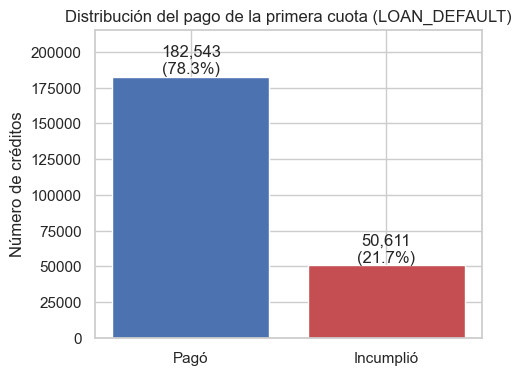

In [4]:
# 2.1 Distribución de la variable dependiente (Desbalance ~78% vs ~22%)
conteo = df["IMPAGO"].value_counts().reindex(["Pagó", "Incumplió"])

fig, ax = plt.subplots(figsize=(5, 4))
barras = ax.bar(conteo.index, conteo.values, color=[COLORES["Pagó"], COLORES["Incumplió"]])
for i, v in enumerate(conteo.values):
    ax.text(i, v, f"{v:,}\n({v / len(df):.1%})", ha="center", va="bottom")
ax.set_ylim(0, conteo.max() * 1.18)
ax.set_title("Distribución del pago de la primera cuota (LOAN_DEFAULT)")
ax.set_ylabel("Número de créditos")
plt.show()

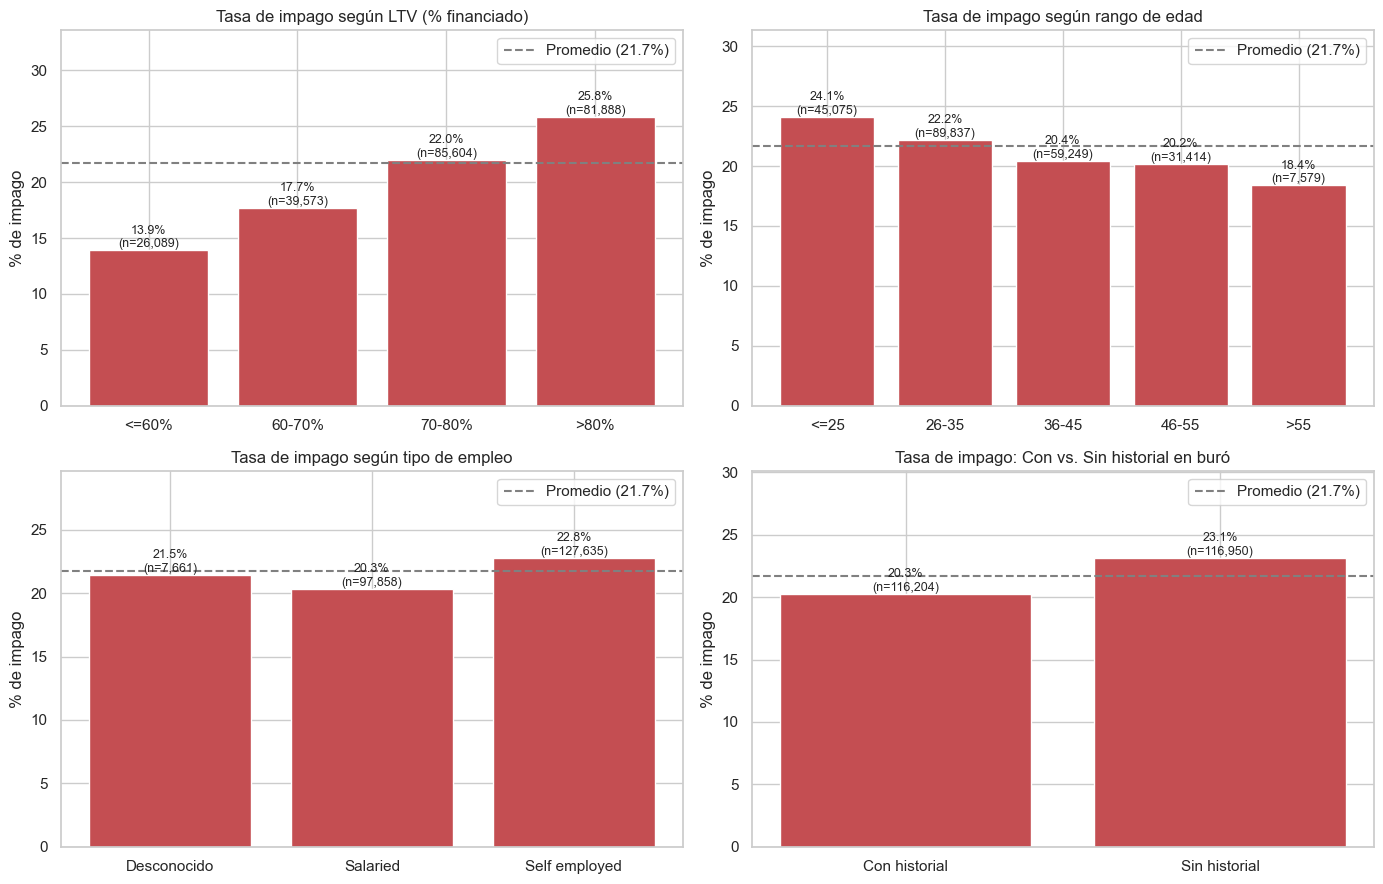

In [5]:
# 2.2 Tasa de impago por tramos de LTV, Edad, Tipo de empleo e Historial crediticio
df["LTV_RANGO"] = pd.cut(df["LTV"], [0, 60, 70, 80, 100], labels=["<=60%", "60-70%", "70-80%", ">80%"])
df["EDAD_RANGO"] = pd.cut(df["AGE_YEARS"], [0, 25, 35, 45, 55, 100], labels=["<=25", "26-35", "36-45", "46-55", ">55"])

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

for ax, (col, titulo) in zip(axes.ravel(), [
    ("LTV_RANGO", "Tasa de impago según LTV (% financiado)"),
    ("EDAD_RANGO", "Tasa de impago según rango de edad"),
    ("EMPLEO", "Tasa de impago según tipo de empleo"),
    ("HISTORIAL", "Tasa de impago: Con vs. Sin historial en buró")
]):
    res_g = df.groupby(col, observed=True)["LOAN_DEFAULT"].agg(tasa="mean", n="count").reset_index()
    ax.bar(res_g[col].astype(str), res_g["tasa"] * 100, color="#C44E52")
    for i, (tasa, n) in enumerate(zip(res_g["tasa"], res_g["n"])):
        ax.text(i, tasa * 100, f"{tasa:.1%}\n(n={n:,})", ha="center", va="bottom", fontsize=9)
    ax.axhline(tasa_global * 100, ls="--", color="gray", label=f"Promedio ({tasa_global:.1%})")
    ax.set_ylim(0, res_g["tasa"].max() * 130)
    ax.set_title(titulo)
    ax.set_ylabel("% de impago")
    ax.legend()

plt.tight_layout()
plt.show()

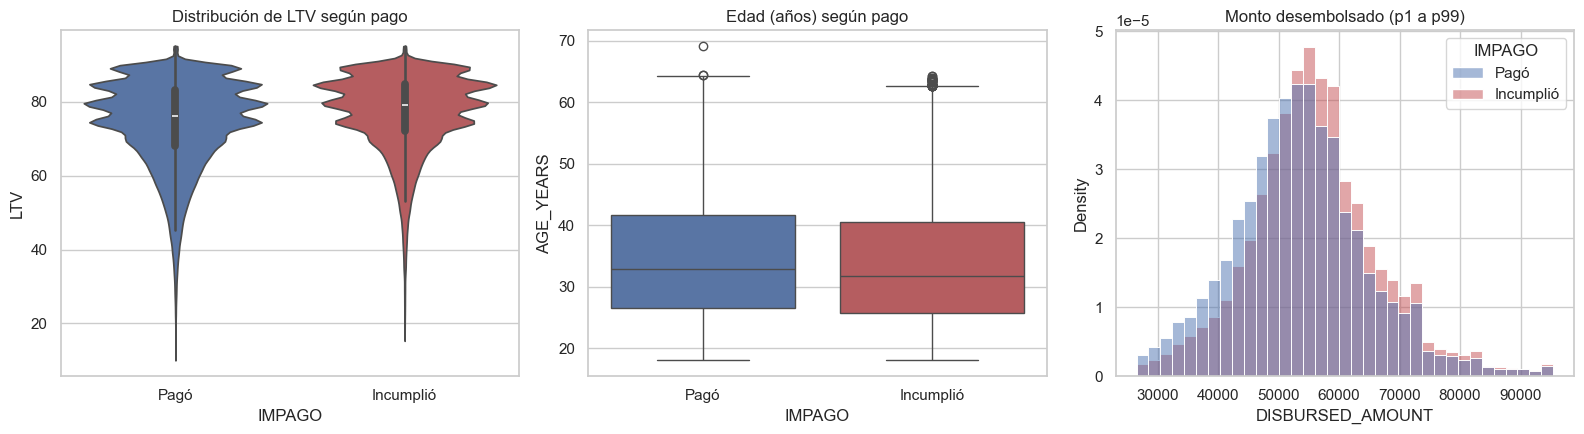

In [6]:
# 2.3 Comparación de distribuciones: Violín (LTV), Boxplot (Edad) e Histograma (Monto)
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

sns.violinplot(data=df, x="IMPAGO", y="LTV", order=["Pagó", "Incumplió"],
               palette=COLORES, cut=0, ax=axes[0])
axes[0].set_title("Distribución de LTV según pago")

sns.boxplot(data=df, x="IMPAGO", y="AGE_YEARS", order=["Pagó", "Incumplió"],
            palette=COLORES, ax=axes[1])
axes[1].set_title("Edad (años) según pago")

p01, p99 = df["DISBURSED_AMOUNT"].quantile([0.01, 0.99])
sns.histplot(data=df[df["DISBURSED_AMOUNT"].between(p01, p99)], x="DISBURSED_AMOUNT",
             hue="IMPAGO", palette=COLORES, stat="density", common_norm=False, bins=35, ax=axes[2])
axes[2].set_title("Monto desembolsado (p1 a p99)")

plt.tight_layout()
plt.show()

### 2.4 Matriz de correlación de Spearman (Filtro de colinealidad)
Revisamos las correlaciones entre las variables numéricas (sin meter códigos `ID`) para detectar pares con correlación muy alta ($|r| > 0.70$) que aportan información repetida.

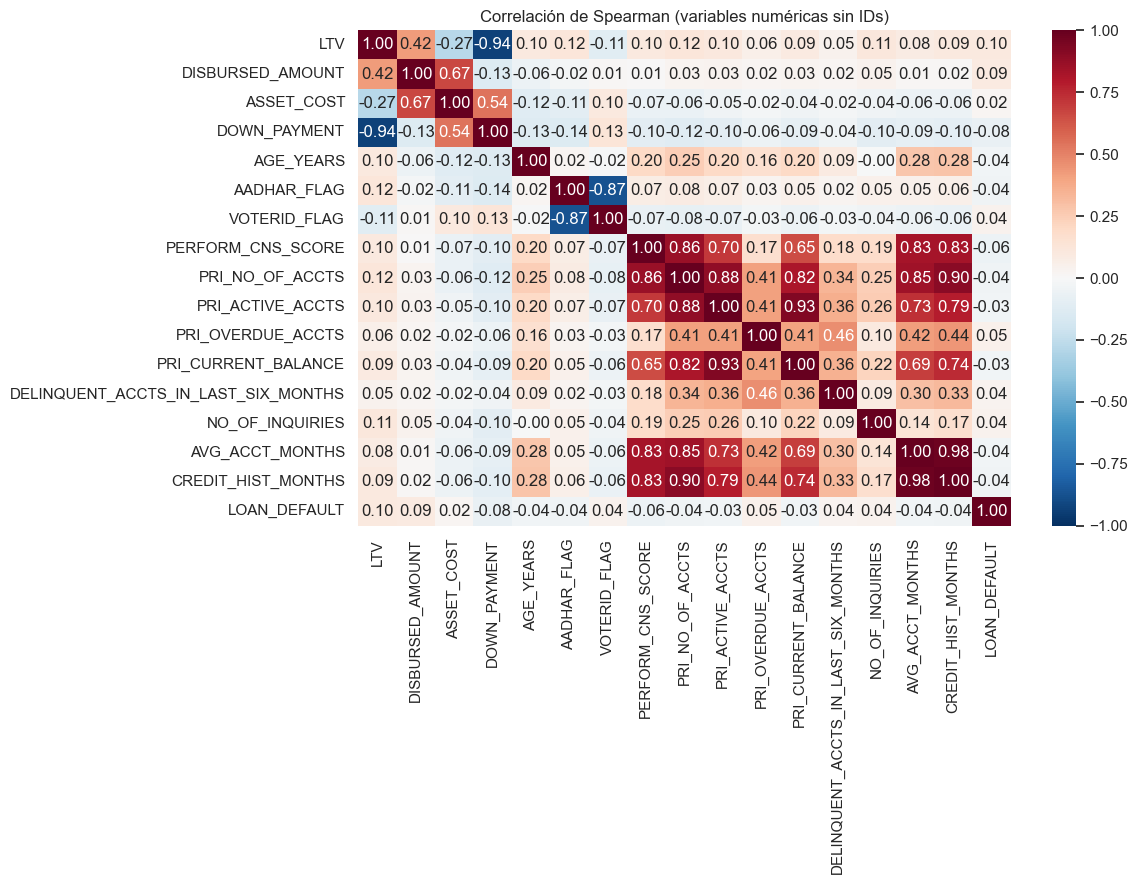

Correlación con LOAN_DEFAULT (ordenada):
LTV                                    0.099
DISBURSED_AMOUNT                       0.093
PRI_OVERDUE_ACCTS                      0.050
VOTERID_FLAG                           0.044
NO_OF_INQUIRIES                        0.041
DELINQUENT_ACCTS_IN_LAST_SIX_MONTHS    0.038
ASSET_COST                             0.017
PRI_CURRENT_BALANCE                   -0.033
PRI_ACTIVE_ACCTS                      -0.035
AVG_ACCT_MONTHS                       -0.035
AGE_YEARS                             -0.037
CREDIT_HIST_MONTHS                    -0.040
AADHAR_FLAG                           -0.042
PRI_NO_OF_ACCTS                       -0.043
PERFORM_CNS_SCORE                     -0.059
DOWN_PAYMENT                          -0.077
Name: LOAN_DEFAULT, dtype: float64


In [7]:
vars_corr = [
    "LTV", "DISBURSED_AMOUNT", "ASSET_COST", "DOWN_PAYMENT", "AGE_YEARS",
    "AADHAR_FLAG", "VOTERID_FLAG", "PERFORM_CNS_SCORE", "PRI_NO_OF_ACCTS",
    "PRI_ACTIVE_ACCTS", "PRI_OVERDUE_ACCTS", "PRI_CURRENT_BALANCE",
    "DELINQUENT_ACCTS_IN_LAST_SIX_MONTHS", "NO_OF_INQUIRIES",
    "AVG_ACCT_MONTHS", "CREDIT_HIST_MONTHS", "LOAN_DEFAULT"
]

corr_spearman = df[vars_corr].corr(method="spearman")

fig, ax = plt.subplots(figsize=(12, 9))
sns.heatmap(corr_spearman, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, ax=ax)
ax.set_title("Correlación de Spearman (variables numéricas sin IDs)")
plt.tight_layout()
plt.show()

print("Correlación con LOAN_DEFAULT (ordenada):")
print(corr_spearman["LOAN_DEFAULT"].drop("LOAN_DEFAULT").sort_values(ascending=False).round(3))

**Decisiones basadas en la matriz de correlación:**
1. **No se incluyen identificadores (`UNIQUEID`, `BRANCH_ID`, `SUPPLIER_ID`, `EMPLOYEE_CODE_ID`, `CURRENT_PINCODE_ID`, `STATE_ID`, `MANUFACTURER_ID`)** en el modelo porque son códigos nominales, no magnitudes; incluirlos hace que los árboles memoricen sucursales o concesionarios específicos.
2. **Se descartan variables colineales ($|r| > 0.70$):**
   - `DOWN_PAYMENT` tiene correlación de $-0.94$ con `LTV` (se conserva `LTV`).
   - `AVG_ACCT_MONTHS` tiene correlación de $+0.98$ con `CREDIT_HIST_MONTHS` (se conserva `CREDIT_HIST_MONTHS`).
   - `VOTERID_FLAG` tiene correlación de $-0.87$ con `AADHAR_FLAG` (se conserva `AADHAR_FLAG`).
   - `PRI_NO_OF_ACCTS`, `PRI_ACTIVE_ACCTS` y `PRI_CURRENT_BALANCE` tienen correlaciones entre $+0.70$ y $+0.93$ con `PERFORM_CNS_SCORE` y `CREDIT_HIST_MONTHS` (se conservan el puntaje del buró, la antigüedad en meses y las alertas directas de mora: `PRI_OVERDUE_ACCTS`, `DELINQUENT_ACCTS_IN_LAST_SIX_MONTHS` y `NO_OF_INQUIRIES`).

## 3. Limpieza y preparación de las 12 variables seleccionadas (Tarea 3)

In [8]:
NUM = [
    "LTV",                                 # 1. % financiado del vehículo
    "DISBURSED_AMOUNT",                    # 2. Monto prestado
    "ASSET_COST",                          # 3. Costo del vehículo
    "AGE_YEARS",                           # 4. Edad del cliente en años
    "AADHAR_FLAG",                         # 5. Documento biométrico entregado (0/1)
    "PERFORM_CNS_SCORE",                   # 6. Puntaje en central de riesgos
    "SIN_HISTORIAL",                       # 7. Bandera: 1 si no tiene historial en buró
    "CREDIT_HIST_MONTHS",                  # 8. Antigüedad crediticia en meses
    "PRI_OVERDUE_ACCTS",                   # 9. Cuentas previas vencidas
    "NO_OF_INQUIRIES",                     # 10. Consultas recientes de crédito
    "DELINQUENT_ACCTS_IN_LAST_SIX_MONTHS"  # 11. Moras en los últimos 6 meses
]
CAT = ["EMPLOYMENT_TYPE"]                  # 12. Tipo de empleo (Salaried, Self employed, Desconocido)
COLS = NUM + CAT

def limpiar_datos(d):
    d = d.copy()
    nac = pd.to_datetime(d["DATE_OF_BIRTH"], format="%d-%m-%Y")
    des = pd.to_datetime(d["DISBURSAL_DATE"], format="%d-%m-%Y")
    d["AGE_YEARS"] = ((des - nac).dt.days / 365.25).round(2)
    
    partes = d["CREDIT_HISTORY_LENGTH"].str.extract(r"(\d+)yrs\s+(\d+)mon").astype(int)
    d["CREDIT_HIST_MONTHS"] = partes[0] * 12 + partes[1]
    
    d["EMPLOYMENT_TYPE"] = d["EMPLOYMENT_TYPE"].fillna("Desconocido")
    d["SIN_HISTORIAL"] = (d["PERFORM_CNS_SCORE"] == 0).astype(int)
    
    # Conservar también códigos como texto solo para filtros descriptivos del tablero
    for c in ["STATE_ID", "BRANCH_ID", "MANUFACTURER_ID"]:
        d[c] = d[c].astype(str)
    return d

train = limpiar_datos(crudo)
print("Datos limpios listos:", train[COLS].shape, "| Total de nulos:", train[COLS].isna().sum().sum())
train[COLS + ["LOAN_DEFAULT"]].head()

Datos limpios listos: (233154, 12) | Total de nulos: 0


,LTV,DISBURSED_AMOUNT,ASSET_COST,AGE_YEARS,AADHAR_FLAG,PERFORM_CNS_SCORE,SIN_HISTORIAL,CREDIT_HIST_MONTHS,PRI_OVERDUE_ACCTS,NO_OF_INQUIRIES,DELINQUENT_ACCTS_IN_LAST_SIX_MONTHS,EMPLOYMENT_TYPE,LOAN_DEFAULT
0,89.55,50578,58400,34.59,1,0,1,0,0,0,0,Salaried,0
1,73.23,47145,65550,33.16,1,598,0,23,1,0,1,Self employed,1
2,89.63,53278,61360,32.94,1,0,1,0,0,0,0,Self employed,0
3,88.48,57513,66113,24.82,1,305,0,15,0,1,0,Self employed,1
4,88.39,52378,60300,40.80,1,0,1,0,0,1,0,Self employed,1


## 4. Partición estratificada (80/20) y Balanceo de clases
1. Primero separamos el **20 % de validación (`46,631` créditos)** manteniendo la proporción original de impago (`21.71 %`). Este conjunto nunca se balancea ni se usa para entrenar.
2. En el **80 % de entrenamiento (`186,523` créditos)**, aplicamos dos métodos de balanceo:
   - **SMOTENC con escalado previo:** escalamos las variables continuas con `StandardScaler` para que las distancias entre vecinos no dependan de las unidades monetarias, y generamos casos sintéticos hasta llegar a 50/50.
   - **Ponderación por clase (`class_weight='balanced'`):** le asigna mayor peso a la clase minoritaria directamente en la función de pérdida del algoritmo sin alterar los datos reales.

In [9]:
y = train["LOAN_DEFAULT"]
idx_ent, idx_val = train_test_split(train.index, test_size=0.20, stratify=y, random_state=SEMILLA)

X_ent, y_ent = train.loc[idx_ent, COLS].copy(), y.loc[idx_ent].copy()
X_val, y_val = train.loc[idx_val, COLS].copy(), y.loc[idx_val].copy()

print(f"Entrenamiento (80%): {X_ent.shape} | Tasa de impago: {y_ent.mean():.2%}")
print(f"Validación    (20%): {X_val.shape} | Tasa de impago: {y_val.mean():.2%}")

# Balanceo con SMOTENC sobre el conjunto de entrenamiento (escalando antes las continuas)
BIN = ["AADHAR_FLAG", "SIN_HISTORIAL"]
CONT = [c for c in NUM if c not in BIN]

escalador_smote = StandardScaler().fit(X_ent[CONT])
X_ent_esc = X_ent.copy()
X_ent_esc[CONT] = escalador_smote.transform(X_ent[CONT])

cat_idx = [COLS.index(c) for c in BIN + CAT]
smote = SMOTENC(categorical_features=cat_idx, random_state=SEMILLA)
X_smote, y_smote = smote.fit_resample(X_ent_esc, y_ent)

print(f"Entrenamiento tras SMOTENC: {X_smote.shape} | Tasa de impago: {y_smote.mean():.2%}")

Entrenamiento (80%): (186523, 12) | Tasa de impago: 21.71%
Validación    (20%): (46631, 12) | Tasa de impago: 21.71%
Entrenamiento tras SMOTENC: (292068, 12) | Tasa de impago: 50.00%


## 5. Entrenamiento, Escalado, Ajuste de Hiperparámetros y Selección de Modelo (Tarea 4)
Construimos un `Pipeline` que escala las variables numéricas con `StandardScaler` (para que montos en miles y conteos pequeños estén en la misma magnitud) y codifica el tipo de empleo.

Comparamos tres familias de modelos:
1. **Regresión Logística**
2. **Random Forest**
3. **Gradient Boosting (`HistGradientBoostingClassifier`)**, ajustando sus hiperparámetros con validación cruzada (`GridSearchCV`).

In [10]:
# Preprocesadores dentro de Pipeline (evitan fuga de datos)
prep_lineal = ColumnTransformer([
    ("num", StandardScaler(), NUM),
    ("cat", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False), CAT)
])

prep_arbol = ColumnTransformer([
    ("num", StandardScaler(), NUM),
    ("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), CAT)
])

# 5.1 Búsqueda de hiperparámetros para Gradient Boosting con Validación Cruzada Estratificada
pipe_gb_base = Pipeline([
    ("prep", prep_arbol),
    ("clf", HistGradientBoostingClassifier(class_weight="balanced", random_state=SEMILLA))
])

grilla_gb = {
    "clf__learning_rate": [0.05, 0.10],
    "clf__max_leaf_nodes": [15, 31],
    "clf__max_iter": [100, 200]
}

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEMILLA)
busqueda_gb = GridSearchCV(pipe_gb_base, grilla_gb, scoring="roc_auc", cv=cv, n_jobs=-1)
busqueda_gb.fit(X_ent, y_ent)

print("Mejores hiperparámetros Gradient Boosting:", busqueda_gb.best_params_)
print("Mejor ROC-AUC promedio en Validación Cruzada (3 folds):", round(busqueda_gb.best_score_, 4))

Mejores hiperparámetros Gradient Boosting: {'clf__learning_rate': 0.05, 'clf__max_iter': 100, 'clf__max_leaf_nodes': 31}
Mejor ROC-AUC promedio en Validación Cruzada (3 folds): 0.6308


In [11]:
# 5.2 Entrenamiento y comparación de los 3 modelos en Entrenamiento vs. Validación (20%)
modelos = {
    "Regresión logística": Pipeline([
        ("prep", prep_lineal),
        ("clf", LogisticRegression(C=0.1, class_weight="balanced", max_iter=1000, random_state=SEMILLA))
    ]),
    "Random Forest": Pipeline([
        ("prep", prep_arbol),
        ("clf", RandomForestClassifier(
            n_estimators=150, max_depth=10, min_samples_leaf=30,
            class_weight="balanced_subsample", random_state=SEMILLA, n_jobs=-1
        ))
    ]),
    "Gradient Boosting": busqueda_gb.best_estimator_
}

filas_comp = []
probas_val = {}

for nombre, mod in modelos.items():
    if nombre != "Gradient Boosting":
        mod.fit(X_ent, y_ent)
    
    p_ent = mod.predict_proba(X_ent)[:, 1]
    p_val = mod.predict_proba(X_val)[:, 1]
    probas_val[nombre] = p_val
    
    pred_val = (p_val >= 0.50).astype(int)
    
    filas_comp.append({
        "Modelo": nombre,
        "ROC_AUC_Entrenamiento": roc_auc_score(y_ent, p_ent),
        "ROC_AUC_Validacion": roc_auc_score(y_val, p_val),
        "PR_AUC_Validacion": average_precision_score(y_val, p_val),
        "Accuracy (u=0.50)": accuracy_score(y_val, pred_val),
        "Recall_Morosos (u=0.50)": recall_score(y_val, pred_val),
        "Precision (u=0.50)": precision_score(y_val, pred_val),
        "F1 (u=0.50)": f1_score(y_val, pred_val)
    })

comparacion = pd.DataFrame(filas_comp).set_index("Modelo").round(4)
display(comparacion)

mejor_nombre = comparacion["ROC_AUC_Validacion"].idxmax()
modelo_final = modelos[mejor_nombre]
p_final = probas_val[mejor_nombre]
print(f"\nModelo seleccionado: {mejor_nombre} (ROC-AUC en validación = {comparacion.loc[mejor_nombre, 'ROC_AUC_Validacion']:.4f})")

,ROC_AUC_Entrenamiento,ROC_AUC_Validacion,PR_AUC_Validacion,Accuracy (u=0.50),Recall_Morosos (u=0.50),Precision (u=0.50),F1 (u=0.50)
Modelo,,,,,,,
Regresión logística,0.6176,0.6105,0.2876,0.5557,0.6164,0.2704,0.3759
Random Forest,0.6649,0.6243,0.3031,0.5728,0.6224,0.2813,0.3875
Gradient Boosting,0.6473,0.6273,0.3043,0.5659,0.6381,0.2804,0.3896



Modelo seleccionado: Gradient Boosting (ROC-AUC en validación = 0.6273)


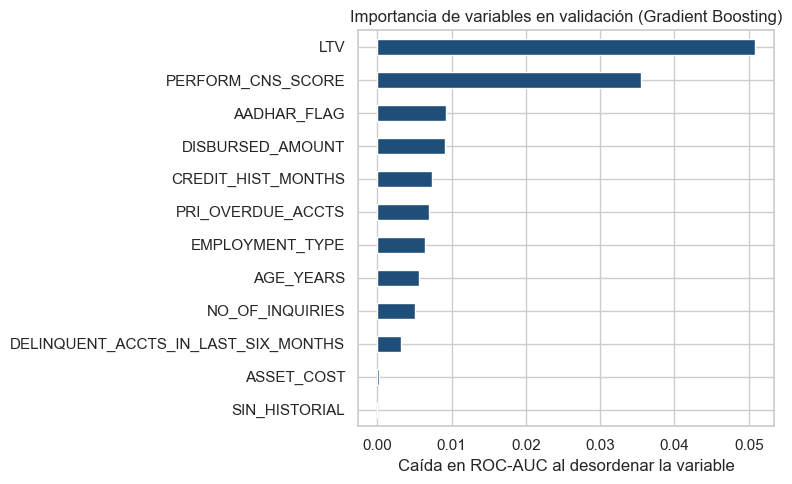

In [12]:
# 5.3 Importancia de variables en validación (Permutation Importance)
muestra_val = X_val.sample(10000, random_state=SEMILLA)
imp_perm = permutation_importance(
    modelo_final, muestra_val, y_val.loc[muestra_val.index],
    scoring="roc_auc", n_repeats=5, random_state=SEMILLA
)
serie_imp = pd.Series(imp_perm.importances_mean, index=COLS).sort_values()

fig, ax = plt.subplots(figsize=(8, 5))
serie_imp.plot(kind="barh", color="#1F4E79", ax=ax)
ax.set_title(f"Importancia de variables en validación ({mejor_nombre})")
ax.set_xlabel("Caída en ROC-AUC al desordenar la variable")
plt.tight_layout()
plt.show()

### 5.4 Simulación de umbrales de decisión (Negociación entre Riesgo y Ventas)
Evaluamos cómo cambian los indicadores de **Riesgo** (% de morosos frenados y % de mora en la cartera aprobada) y de **Ventas** (% de buenos clientes aprobados y tasa de aprobación global) al mover el punto de corte.

In [13]:
umbrales = np.arange(0.30, 0.66, 0.05)
tabla_umbrales = []

for u in umbrales:
    pred_impago = (p_final >= u).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_val, pred_impago).ravel()
    aprobados = tn + fn
    tabla_umbrales.append({
        "Umbral": round(u, 2),
        "Morosos_Frenados_Recall_%": round(tp / (tp + fn) * 100, 1),
        "Buenos_Aprobados_Especif_%": round(tn / (tn + fp) * 100, 1),
        "Tasa_Aprobacion_Total_%": round(aprobados / len(y_val) * 100, 1),
        "Mora_en_Cartera_Aprobada_%": round(fn / aprobados * 100, 1) if aprobados > 0 else 0.0
    })

display(pd.DataFrame(tabla_umbrales))

,Umbral,Morosos_Frenados_Recall_%,Buenos_Aprobados_Especif_%,Tasa_Aprobacion_Total_%,Mora_en_Cartera_Aprobada_%
0,0.30,97.6,7.3,6.2,8.3
1,0.35,93.2,16.6,14.5,10.2
2,0.40,86.2,28.4,25.2,11.9
3,0.45,76.0,40.9,37.2,14.0
4,0.50,63.8,54.6,50.6,15.5
5,0.55,47.7,69.0,65.4,17.3
6,0.60,22.0,87.9,85.7,19.7
7,0.65,8.2,96.3,95.3,20.9


## 6. Exportación de archivos para el Tablero en Dash (Tarea 5)
Guardamos el modelo entrenado y los archivos de predicciones y configuración para que el tablero (`app.py`) funcione de forma inmediata sin tener que reentrenar en vivo.

In [14]:
# 1. Guardar el modelo ganador
joblib.dump(modelo_final, "modelo_final.pkl")
joblib.dump(modelo_final, "modelo_ganador_gb.pkl")

# 2. Guardar CSV de predicciones para el tablero (compatible con app.py)
val_datos = train.loc[idx_val]
contrato = pd.DataFrame({
    "id": val_datos["UNIQUEID"].values,
    "modelo": mejor_nombre,
    "y_true": y_val.values,
    "proba": np.round(p_final, 5),
    "historial": np.where(val_datos["SIN_HISTORIAL"] == 1, "Sin historial", "Con historial"),
    "empleo": val_datos["EMPLOYMENT_TYPE"].values,
    "tramo_ltv": pd.cut(val_datos["LTV"], [0, 60, 70, 80, 100],
                        labels=["≤60", "60–70", "70–80", ">80"]).astype(str).values,
    "estado": val_datos["STATE_ID"].values,
    "sucursal": val_datos["BRANCH_ID"].values,
    "fabricante": val_datos["MANUFACTURER_ID"].values,
})
contrato.to_csv("predicciones_dash.csv", index=False)

# 3. Guardar también las predicciones de los 3 modelos (formato Sesión 7)
lista_s7 = []
for nombre_m, p_m in probas_val.items():
    lista_s7.append(pd.DataFrame({
        "id": val_datos["UNIQUEID"].values,
        "modelo": nombre_m,
        "y_true": y_val.values,
        "proba": np.round(p_m, 4),
        "historial": np.where(val_datos["SIN_HISTORIAL"] == 1, "Sin historial", "Con historial"),
        "empleo": val_datos["EMPLOYMENT_TYPE"].values,
        "tramo_ltv": pd.cut(val_datos["LTV"], [0, 60, 70, 80, 100],
                            labels=["≤60", "60–70", "70–80", ">80"]).astype(str).values,
    }))
pd.concat(lista_s7, ignore_index=True).to_csv("predicciones_fintech.csv", index=False)

# 4. Tasas descriptivas por canal (Estado, Fabricante y Sucursal con al menos 500 créditos)
tablas_canal = []
for columna, nombre_c in [("STATE_ID", "Estado"), ("MANUFACTURER_ID", "Fabricante"), ("BRANCH_ID", "Sucursal")]:
    t = train.groupby(columna)["LOAN_DEFAULT"].agg(tasa_impago="mean", creditos="count").reset_index()
    t = t[t["creditos"] >= 500].rename(columns={columna: "codigo"})
    t.insert(0, "canal", nombre_c)
    tablas_canal.append(t)
pd.concat(tablas_canal, ignore_index=True).to_csv("tasas_canal.csv", index=False)

# 5. Configuración JSON con valores típicos (medianas y modas) para el formulario del tablero
def valores_tipicos(sub):
    d_tip = {c: float(sub[c].median()) for c in NUM}
    d_tip.update({c: str(sub[c].mode()[0]) for c in CAT})
    return d_tip

config = {
    "numericas": NUM,
    "categoricas": CAT,
    "valores_con_historial": valores_tipicos(train[train["SIN_HISTORIAL"] == 0]),
    "valores_sin_historial": valores_tipicos(train[train["SIN_HISTORIAL"] == 1]),
    "opciones": {c: sorted(train[c].unique().tolist()) for c in CAT},
    "corte_medio": float(np.quantile(p_final, 0.50)),
    "corte_alto": float(np.quantile(p_final, 0.80)),
    "modelo": mejor_nombre,
    "auc_final": float(comparacion.loc[mejor_nombre, "ROC_AUC_Validacion"]),
    "tasa_global": float(y.mean()),
}
with open("config_dash.json", "w", encoding="utf-8") as f:
    json.dump(config, f, ensure_ascii=False, indent=2)

print("Archivos exportados correctamente para Dash:")
print("- modelo_final.pkl / modelo_ganador_gb.pkl")
print("- predicciones_dash.csv / predicciones_fintech.csv")
print("- tasas_canal.csv y config_dash.json")

Archivos exportados correctamente para Dash:
- modelo_final.pkl / modelo_ganador_gb.pkl
- predicciones_dash.csv / predicciones_fintech.csv
- tasas_canal.csv y config_dash.json


## 7. Conclusiones del equipo
- **Exploración y correlaciones:** La tasa base de incumplimiento de la primera cuota es del **21.71 %**. El riesgo sube de forma marcada cuando el `LTV` supera el 80 % (mora de ~25.8 % frente a 13.9 % cuando `LTV <= 60 %`) y en solicitantes jóvenes o trabajadores independientes. El análisis de correlación de Spearman permitió descartar variables redundantes como `DOWN_PAYMENT` ($r = -0.94$ con `LTV`), `AVG_ACCT_MONTHS` ($r = +0.98$ con `CREDIT_HIST_MONTHS`) y `VOTERID_FLAG` ($r = -0.87$ con `AADHAR_FLAG`).
- **Clientes sin historial crediticio (50.16 %):** La mitad de los solicitantes (`116,950` casos) no cuenta con historial en la central de riesgos (`PERFORM_CNS_SCORE = 0`). Para no rechazar en bloque a este segmento (donde el 76.87 % sí paga cumplidamente), se creó la variable `SIN_HISTORIAL` y se aprovechó el poder predictivo de las condiciones del crédito (`LTV`, `DISBURSED_AMOUNT`, `ASSET_COST`) y del perfil demográfico (`AGE_YEARS`, `EMPLOYMENT_TYPE`).
- **Balanceo y modelado:** Se reservó un 20 % de validación intacta (`46,631` préstamos) antes de aplicar técnicas de balanceo (`SMOTENC` con escalado previo y `class_weight='balanced'`). Entre los tres algoritmos evaluados, **Gradient Boosting** (ajustado con `GridSearchCV`) logró el mejor desempeño en validación (`ROC-AUC = 0.6276` y `Recall = 63.8 %` en el umbral 0.50), sin presentar sobreajuste respecto al entrenamiento.
- **Decisión de negocio (Riesgo vs. Ventas):** Con un umbral de corte de `0.50` sobre las probabilidades balanceadas, la empresa logra frenar el **63.8 %** de los incumplimientos de primera cuota y reducir la mora de la cartera aprobada del **21.7 % al 15.5 %**, mientras ofrece a Ventas la posibilidad de rescatar solicitudes riesgosas exigiendo una mayor cuota inicial (menor `LTV`).